In [1]:
import numpy as np 
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

                 HR DATASET
                     ↓
                  EDA
                     ↓
       ┌─────────────┴─────────────┐
       ↓                           ↓
 Numerical                     Categorical
       ↓                           ↓
 Missing values               Missing values
       ↓                           ↓
 Scaling                      Encoding
       └─────────────┬─────────────┘
                     ↓
             Feature Engineering
                     ↓
              ColumnTransformer
                     ↓
                 Pipeline
                     ↓
              Classification Model
                     ↓
              Evaluation

In [2]:

aug = pd.read_csv('aug_train.csv')


In [3]:
aug.isnull().mean()*100

enrollee_id                0.000000
city                       0.000000
city_development_index     0.000000
gender                    23.530640
relevent_experience        0.000000
enrolled_university        2.014824
education_level            2.401086
major_discipline          14.683161
experience                 0.339284
company_size              30.994885
company_type              32.049274
last_new_job               2.207955
training_hours             0.000000
target                     0.000000
dtype: float64

In [135]:
aug.head()

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,never,83,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,never,52,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0.0


In [136]:
aug['target'].value_counts()

target
0.0    14381
1.0     4777
Name: count, dtype: int64

In [137]:
aug['relevent_experience'].value_counts()

relevent_experience
Has relevent experience    13792
No relevent experience      5366
Name: count, dtype: int64

In [138]:
aug.isnull().mean()

enrollee_id               0.000000
city                      0.000000
city_development_index    0.000000
gender                    0.235306
relevent_experience       0.000000
enrolled_university       0.020148
education_level           0.024011
major_discipline          0.146832
experience                0.003393
company_size              0.309949
company_type              0.320493
last_new_job              0.022080
training_hours            0.000000
target                    0.000000
dtype: float64

In [139]:
aug.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   enrollee_id             19158 non-null  int64  
 1   city                    19158 non-null  object 
 2   city_development_index  19158 non-null  float64
 3   gender                  14650 non-null  object 
 4   relevent_experience     19158 non-null  object 
 5   enrolled_university     18772 non-null  object 
 6   education_level         18698 non-null  object 
 7   major_discipline        16345 non-null  object 
 8   experience              19093 non-null  object 
 9   company_size            13220 non-null  object 
 10  company_type            13018 non-null  object 
 11  last_new_job            18735 non-null  object 
 12  training_hours          19158 non-null  int64  
 13  target                  19158 non-null  float64
dtypes: float64(2), int64(2), object(10)
me

In [140]:
aug.drop(columns=['enrollee_id'], inplace=True)

In [141]:
aug.head()

,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1.0
1,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0.0
2,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,never,83,0.0
3,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,never,52,1.0
4,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0.0


## Categorical

In [142]:
aug.head(2)

,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1.0
1,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0.0


<Axes: xlabel='major_discipline', ylabel='count'>

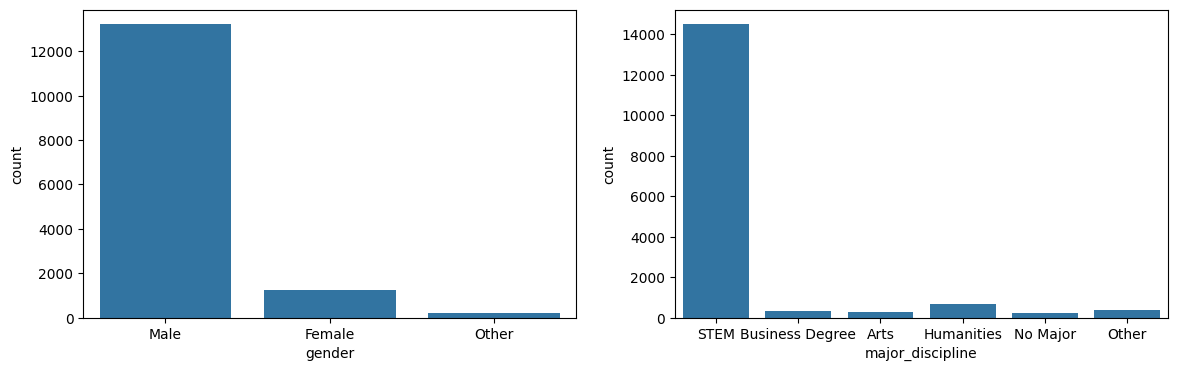

In [143]:
plt.figure(figsize=(14,4))

plt.subplot(121)
sns.countplot(x =aug['gender'])

plt.subplot(122)
sns.countplot(x = aug['major_discipline'])




<Axes: xlabel='relevent_experience', ylabel='count'>

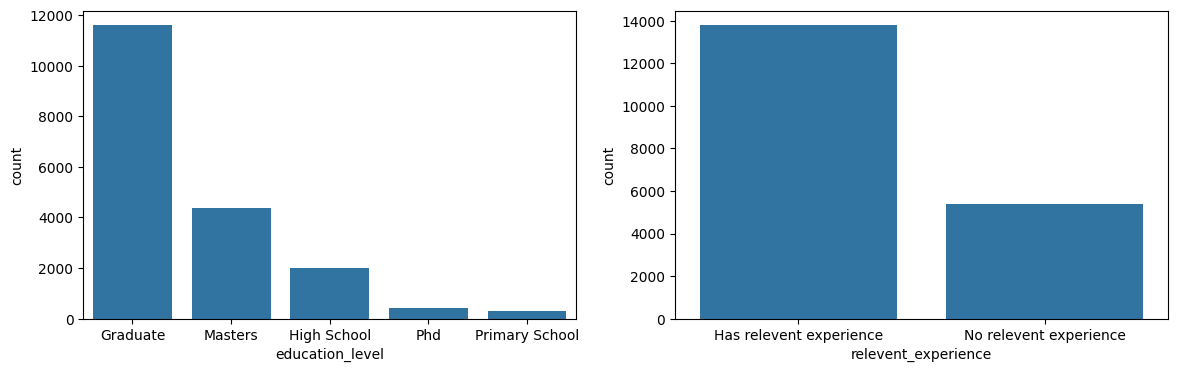

In [144]:
plt.figure(figsize=(14,4))
plt.subplot(121)
sns.countplot(x = aug['education_level'])

plt.subplot(122)
sns.countplot(x = aug['relevent_experience'])

In [145]:
aug.head(2)

,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1.0
1,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0.0


In [146]:
aug['city_development_index'].value_counts()

city_development_index
0.920    5200
0.624    2702
0.910    1533
0.926    1336
0.698     683
         ... 
0.649       4
0.807       4
0.781       3
0.625       3
0.664       1
Name: count, Length: 93, dtype: int64

<Axes: xlabel='city_development_index', ylabel='Density'>

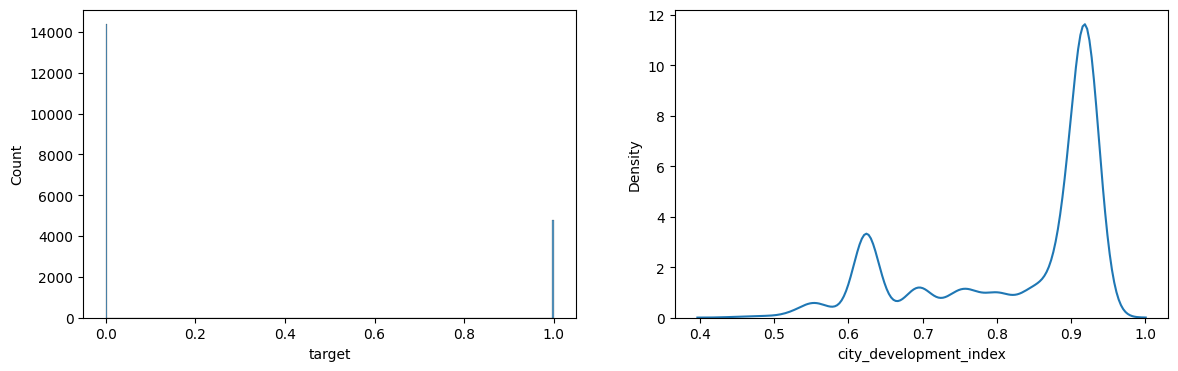

In [147]:
plt.figure(figsize=(14,4))

plt.subplot(121)
sns.histplot(aug['target'])

plt.subplot(122)
sns.kdeplot(aug['city_development_index'])

<Axes: ylabel='training_hours'>

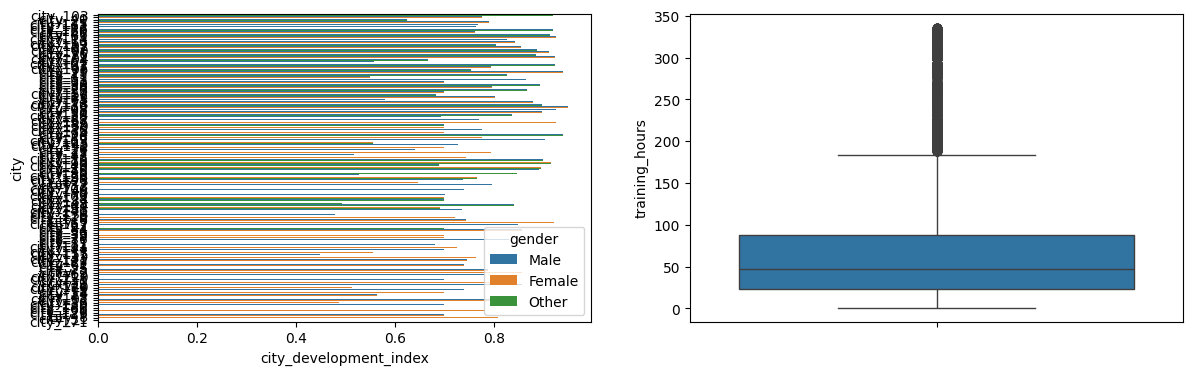

In [148]:
plt.figure(figsize=(14,4))

plt.subplot(121)
sns.barplot(y=aug['city'], x=aug['city_development_index'], hue=aug['gender'])

plt.subplot(122)
sns.boxplot(aug['training_hours'])

In [149]:
aug.head(2)

,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1.0
1,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0.0


<Axes: xlabel='major_discipline', ylabel='city_development_index'>

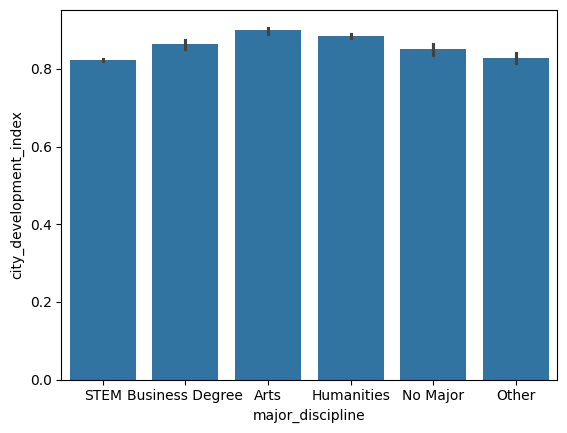

In [150]:
sns.barplot(y = aug['city_development_index'], x = aug['major_discipline'])

In [151]:
aug.head(2)

,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1.0
1,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0.0


<Axes: xlabel='education_level', ylabel='count'>

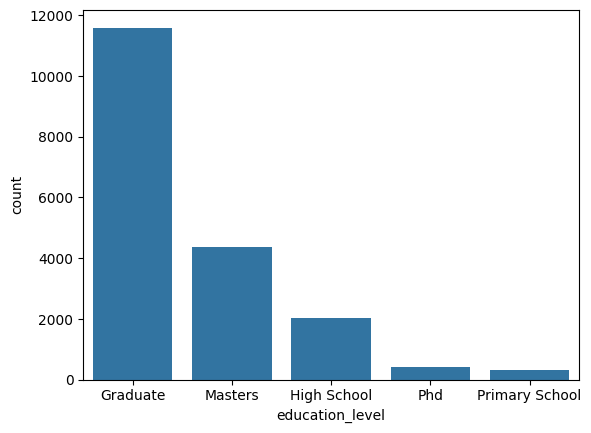

In [152]:
sns.countplot(x = aug['education_level'])

In [153]:
from ydata_profiling import ProfileReport
prof = ProfileReport(aug)
prof.to_file(output_file="output.html")

Export report to file: 100%|██████████| 1/1 [00:00<00:00, 472.60it/s]


In [18]:
st = pd.read_csv('IPL_2008-2020.csv')

In [19]:
st.isnull().mean()*100

id                  0.000000
city                1.593137
date                0.000000
player_of_match     0.490196
venue               0.000000
neutral_venue       0.000000
team1               0.000000
team2               0.000000
toss_winner         0.000000
toss_decision       0.000000
winner              0.490196
result              0.490196
result_margin       2.083333
eliminator          0.490196
method             97.671569
umpire1             0.000000
umpire2             0.000000
dtype: float64

In [21]:
st.shape

(816, 17)